In [2]:
## IMPORTS
import torch
import matplotlib.pyplot as plt

In [3]:
## TRACKER FOR GRADIENT EVALUATIONS
def tracker(mode):
  global num_evals
  if mode == 's':
    num_evals = 0
  elif mode == 'i':
    num_evals += 1
  elif mode == 'r':
    return num_evals
  else:
    print(f"Unknown mode: {mode}")

In [4]:
## FUNCTION AND GRADIENT
def f(x):
    # x[0] = slow direction, x[1] = fast direction
  value = torch.sum(x**2)
  return value
# Compute the gradient
def grad_f(x):
    dim = x.shape[0]
    assert x.shape == (dim, 1)

    # Ensure x requires gradients
    x = x.clone().detach().requires_grad_()  # Re-create x with requires_grad if necessary

    y = f(x)  # Call the function to get f(x)

    # Compute the gradient
    dy = torch.autograd.grad(outputs=y, inputs=x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

    tracker('i')
    return dy  # Return the computed gradient


In [5]:
def gradient_descent(f, grad_f, step_size, x0, tol=1e-3, max_iters=100):
  x_hist = []
  f_hist = []
  grad_norm_hist = []

  x = x0.clone().detach().requires_grad_()

  # store values at 0th iteration
  x_hist.append(x.detach())
  fx = f(x)
  grad_fx = grad_f(x)
  grad_norm_term = torch.norm(grad_fx)

  f_hist.append(fx.detach())
  grad_norm_hist.append(grad_norm_term.detach())

  total_iters = 0

  for i in range(max_iters):
    # gradient descent update
    x = x - step_size * grad_fx
    x = x.clone().detach().requires_grad_()

    grad_fx = grad_f(x)
    fx = f(x)
    grad_norm = torch.norm(grad_fx)

    # store values
    x_hist.append(x.detach())
    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm.detach())

    print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

    total_iters += 1

    if grad_norm <= tol:
      print('converged!')
      break

  x_opt = x.detach()
  return x_opt, f_hist, grad_norm_hist, x_hist, total_iters


In [6]:
## RK4

def runge_kutta_4(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):
    x_hist = []
    f_hist = []
    grad_norm_hist = []

    x = x0.clone().detach().requires_grad_()

    # store values at 0th iteration
    x_hist.append(x.detach())
    fx = f(x)
    grad_fx = grad_f(x)
    grad_norm_term = torch.norm(grad_fx)

    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm_term.detach())

    total_iters = 0

    for i in range(max_iters):
        k1 = -grad_f(x)

        x_k2 = (x + 0.5 * step_size * k1).clone().detach().requires_grad_()
        k2 = -grad_f(x_k2)

        x_k3 = (x + 0.5 * step_size * k2).clone().detach().requires_grad_()
        k3 = -grad_f(x_k3)

        x_k4 = (x + step_size * k3).clone().detach().requires_grad_()
        k4 = -grad_f(x_k4)

        dx = (step_size / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        x = x + dx
        x = x.clone().detach().requires_grad_()

        fx = f(x)
        grad_fx = -k1
        grad_norm = torch.norm(grad_fx)

        x_hist.append(x.detach())
        f_hist.append(fx.detach())
        grad_norm_hist.append(grad_norm.detach())

        print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

        total_iters += 1

        if grad_norm <= tol:
            print("converged!")
            break

    return x.detach(), f_hist, grad_norm_hist, x_hist, total_iters

In [7]:
## AB3
def Adams_Bashforth3(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):

  # Save x at each iteration for plotting
  x_hist = []
  # Save f at each iteration for plotting
  f_hist = []
  # Save gradient norm at each iteration for plotting
  # This one is pretty important since we want it to go to zero
  grad_norm_hist = []
  # want a histogram of the gradients since we can't calculate the gradient
  # with previous x since it was detached
  grad_hist = []
  x = x0

  # Set x.requires_grad = True
  x.requires_grad = True

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  # append the first grad_fx
  grad_hist.append(grad_fx)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term).detach())

  total_iters = 0

  for i in range(max_iters):
    # Gradient descent update
    # Do euler's to get the first step (only one x)
    if i == 0:
      x = x - step_size * grad_hist[i]
    # Now do AB2 (only two x)
    elif i == 1:
      x = x - step_size * (3/2*grad_hist[i]  - 1/2 * grad_hist[i-1])
    # Finally, we can do AB3 (there are enough x's now)
    else:
      x = x - step_size * (23/12*grad_hist[i]  - 16/12 * grad_hist[i-1] + 5/12 * grad_hist[i-2])

    # evaluate
    grad_fx = grad_f(x)
    fx = f(x)
    grad_hist.append(grad_fx)

    # For plotting
    grad_norm = torch.norm(grad_fx)

    # Store values
    x_hist.append(x.detach())
    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm.detach())

    # Print Values
    print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

    total_iters += 1

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist, total_iters

In [8]:
def backward_euler_descent(f, grad_f, step_size, x0, tol=1e-3, max_iters=100, inner_iters=10, inner_tol=1e-1):
    x_hist = []
    f_hist = []
    grad_norm_hist = []

    x = x0.clone().detach().requires_grad_(True)

    # Initial eval
    fx = f(x)
    grad_fx = grad_f(x)
    grad_norm = torch.norm(grad_fx)

    x_hist.append(x.clone().detach())
    f_hist.append(fx.item())
    grad_norm_hist.append(grad_norm.item())

    total_iters = 0

    for i in range(max_iters):
        x_new = x.clone().detach().requires_grad_(True)

        for j in range(inner_iters):
            grad = grad_f(x_new)
            x_candidate = x - step_size * grad

            # Residual is the change between x_new and the updated x_candidate
            residual = torch.norm(x_candidate - x_new).item()
            print(f'    inner_iter: {j}, residual: {residual:.3e}')

            # Check for convergence of inner loop
            if residual < inner_tol:
                print(f'    inner loop converged at iter {j} with residual {residual:.3e}')
                x_new = x_candidate.clone().detach().requires_grad_(True)
                break

            x_new = x_candidate.clone().detach().requires_grad_(True)

        x = x_new.clone().detach().requires_grad_(True)
        fx = f(x)
        grad_fx = grad_f(x)
        grad_norm = torch.norm(grad_fx)

        x_hist.append(x.clone().detach())
        f_hist.append(fx.item())
        grad_norm_hist.append(grad_norm.item())

        print(f'i: {i}, fx: {fx.item():.3e}, grad_norm: {grad_norm.item():.3e}')

        total_iters += 1

        if grad_norm <= tol:
            print('converged!')
            break

    return x, f_hist, grad_norm_hist, x_hist, total_iters


In [9]:
## AM3

def adamsMoulton (f, grad_f, step_size, x0, tol=1e-3, max_iters=1000, inner_iters = 100, inner_tol = 1e-1):

  x_hist = []
  f_hist = []
  grad_hist = []

  # Save gradient norm at each iteration for plotting
  grad_norm_hist = []
  x = x0

  x = x.detach().clone().requires_grad_(True)

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term).detach())

  total_iters = 0

  for i in range(max_iters):
    # Gradient descent update
    if i==0:
      grad_fx = grad_f(x)
      grad_hist.append(grad_fx.detach())
      x = x - step_size * grad_fx
    elif i == 1:
        grad_fx = grad_f(x)                      # ✅ Add this
        grad_hist.append(grad_fx.detach())       # ✅ So grad_hist[1] is defined

        x_new = x.clone().detach().requires_grad_(True)
        for j in range(inner_iters):
            grad = grad_f(x_new)
            x_new = (x - step_size * (1/12)* ((5 * grad + 8 * grad_hist[i] - grad_hist[i - 1]))).detach().requires_grad_(True)
            res = torch.norm(x - x_new)
            print(f"{j}: Residual: {res}")
            if res < inner_tol:
                print("Inner Converged!")
                break
        x = x_new.clone().detach().requires_grad_(True)
        grad_fx = grad_f(x)
        grad_hist.append(grad_fx.detach())
    else:
        x_candidate = x.clone().detach().requires_grad_(True)
        for j in range(inner_iters):
            x_next = x - (step_size / 24) * (
                9 * grad_f(x_candidate) +
                19 * grad_hist[i] -
                5 * grad_hist[i - 1] +
                grad_hist[i - 2]
            )
            residual = torch.norm(x_candidate - x_next).item()
            print(f'    inner_iter: {j}, residual: {residual:.3e}')
            if residual < inner_tol:
                break
            x_candidate = x_next.clone().detach().requires_grad_(True)
        x = x_next.clone().detach().requires_grad_(True)
        grad_fx = grad_f(x)
        grad_hist.append(grad_fx.detach())  # ✅ Update grad history



    fx = f(x)
    grad_fx = grad_f(x)
    grad_norm = torch.norm(grad_fx)

    x_hist.append(x.clone().detach())
    f_hist.append(fx.item())
    grad_norm_hist.append(grad_norm.item())

    print(f'i: {i}, fx: {fx.item():.3e}, grad_norm: {grad_norm.item():.3e}')

    total_iters += 1

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist, total_iters

In [10]:
dim = 2
max_iters = 2000
x0 = torch.randn(dim, 1)
tol = 1e-4

In [11]:
# step_size = 0.5
# x0 = torch.randn(dim,1)
# # GD
# tracker('s')
# x_opt_gd, f_hist_gd, grad_norm_hist_gd, x_hist_gd, total_iters = gradient_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for GD: {tracker('r')}")

In [12]:
# step_size = 0.7
# x0 = torch.randn(dim,1)
# # RK4
# tracker('s')
# x_opt_rk4, f_hist_rk4, grad_norm_hist_rk4, x_hist_rk4, total_iters = runge_kutta_4(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for RK4: {tracker('r')}")


In [13]:
# x0 = torch.randn(dim,1)
# step_size = 0.5
# # AB3
# tracker('s')
# x_opt_be, f_hist_be, grad_norm_hist_be, x_hist_be, total_iters = Adams_Bashforth3(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for AB3: {tracker('r')}")

In [14]:
# step_size = 0.4
# x0 = torch.randn(dim,1)
# # Backward Euler
# tracker('s')
# x_opt_be, f_hist_be, grad_norm_hist_be, x_hist_be, total_iters = backward_euler_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for backward euler: {tracker('r')}")


In [15]:
# step_size = 0.175 # best num of eval so far: 2682 w/ step size 0.175
# x0 = torch.randn(dim,1)
# # # AM3
# tracker('s')
# x_opt_am, f_hist_am, grad_norm_hist_am, x_hist_am, total_iters = adamsMoulton(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for AM3: {tracker('r')}")

In [16]:
## EVALUATIONS

GDSum = 0
RKSum = 0
ABSum = 0
BESum = 0
AMSum = 0

GDSum2 = 0
RKSum2 = 0
ABSum2 = 0
BESum2 = 0
AMSum2 = 0

for _ in range(5):
  # random x
  x0 = 5*torch.randn(dim,1)

  step_size = 0.5
  tracker('s')
  x_opt_gd, f_hist_gd, grad_norm_hist_gd, x_hist_gd, total_iters = gradient_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  GDSum2 += total_iters
  GDSum += tracker('r')
  tracker('s')
  step_size = 0.7
  x_opt_rk4, f_hist_rk4, grad_norm_hist_rk4, x_hist_rk4, total_iters = runge_kutta_4(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  RKSum += tracker('r')
  RKSum2 += total_iters
  tracker('s')
  step_size = 0.5
  x_opt_ab, f_hist_ab, grad_norm_hist_ab, x_hist_ab, total_iters = Adams_Bashforth3(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  ABSum += tracker('r')
  ABSum2 += total_iters
  step_size = 0.4
  tracker('s')
  x_opt_be, f_hist_be, grad_norm_hist_be, x_hist_be, total_iters = backward_euler_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  BESum += tracker('r')
  BESum2 += total_iters
  step_size = 0.5
  tracker('s')
  x_opt_am, f_hist_am, grad_norm_hist_am, x_hist_am, total_iters = adamsMoulton(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters, inner_iters=10)
  AMSum += tracker('r')
  AMSum2 += total_iters

print(f"AVG Grad Evals for GD: {GDSum/5} AVG Steps for GD: {GDSum2/5}")
print(f"AVG Grad Evals for RK4: {RKSum/5} AVG Steps for RK4: {RKSum2/5}")
print(f"AVG Grad Evals for AB3: {ABSum/5} AVG Steps for AB3: {ABSum2/5}")
print(f"AVG Grad Evals for BE: {BESum/5} AVG Steps for BE: {BESum2/5}")
print(f"AVG Grad Evals for AM3: {AMSum/5} AVG Steps for AM3: {AMSum2/5}")

i: 0, fx: 0.000e+00, grad_norm: 0.000e+00
converged!
i: 0, fx: 6.235e+00, grad_norm: 1.766e+01
i: 1, fx: 4.984e-01, grad_norm: 4.994e+00
i: 2, fx: 3.985e-02, grad_norm: 1.412e+00
i: 3, fx: 3.185e-03, grad_norm: 3.992e-01
i: 4, fx: 2.546e-04, grad_norm: 1.129e-01
i: 5, fx: 2.035e-05, grad_norm: 3.191e-02
i: 6, fx: 1.627e-06, grad_norm: 9.023e-03
i: 7, fx: 1.301e-07, grad_norm: 2.551e-03
i: 8, fx: 1.040e-08, grad_norm: 7.213e-04
i: 9, fx: 8.311e-10, grad_norm: 2.039e-04
i: 10, fx: 6.644e-11, grad_norm: 5.766e-05
converged!
i: 0, fx: 0.000e+00, grad_norm: 0.000e+00
converge!
    inner_iter: 0, residual: 7.066e+00
    inner_iter: 1, residual: 5.652e+00
    inner_iter: 2, residual: 4.522e+00
    inner_iter: 3, residual: 3.618e+00
    inner_iter: 4, residual: 2.894e+00
    inner_iter: 5, residual: 2.315e+00
    inner_iter: 6, residual: 1.852e+00
    inner_iter: 7, residual: 1.482e+00
    inner_iter: 8, residual: 1.185e+00
    inner_iter: 9, residual: 9.483e-01
i: 0, fx: 2.839e+01, grad_norm:

In [17]:
# step_size = 0.5
# tracker('s')
# x_opt_am, f_hist_am, grad_norm_hist_am, x_hist_am, total_iters = adamsMoulton(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters, inner_iters=10)
# AMSum += tracker('r')
# AMSum2 += total_iters

In [18]:
#plot solution paths
#create 2D grid from -5 to 5

#define range and number of pts
xx = torch.linspace(-5,5,100)
yy = torch.linspace(-5,5,100)

# creat grid
X, Y = torch.meshgrid(xx, yy, indexing = 'xy') # 'xy' ensures correct indexing for 2D grid

Z = torch.zeros(X.shape)
for i in range(100):
  for j in range(100):
    input_vec = torch.tensor([X[i,j], Y[i,j]]).view(2,1)
    # put in function
    Z[i,j] = f(input_vec).item()

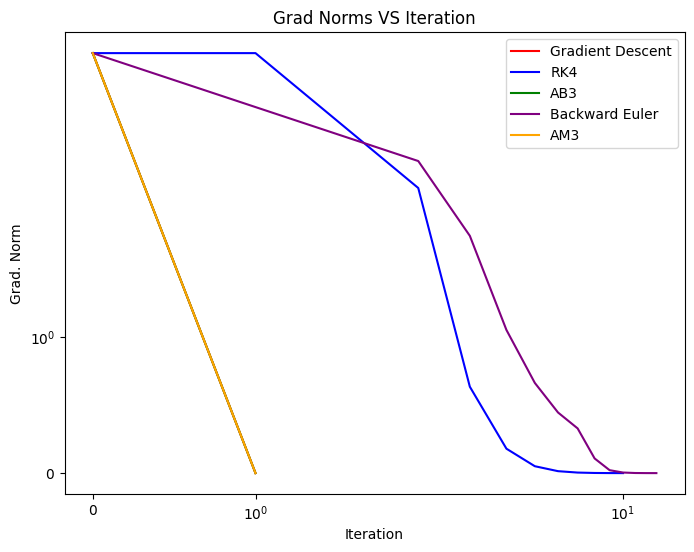

In [19]:
# GD
# plot grad norm vs itr
plt.figure(figsize=(8,6))
plt.plot(grad_norm_hist_gd, color = "red", label="Gradient Descent")
# plt.title("GD: Grad. Norm vs. Iteration")

# RK4
# plot grad norm vs itr
plt.plot(grad_norm_hist_rk4, color="blue", label = 'RK4' )

# # AB3
# # plot grad norm vs itr
plt.plot(grad_norm_hist_ab, color="green", label ="AB3")

# Back-Euler
# plot grad norm vs itr
plt.plot(grad_norm_hist_be, color='purple', label = "Backward Euler")
# AM3
# plot grad norm vs itr
plt.plot(grad_norm_hist_am, color = 'orange', label= 'AM3')
plt.xlabel("Iteration")
plt.ylabel("Grad. Norm")
plt.yscale('symlog')
plt.xscale('symlog')
plt.title("Grad Norms VS Iteration")
plt.legend()
plt.show()

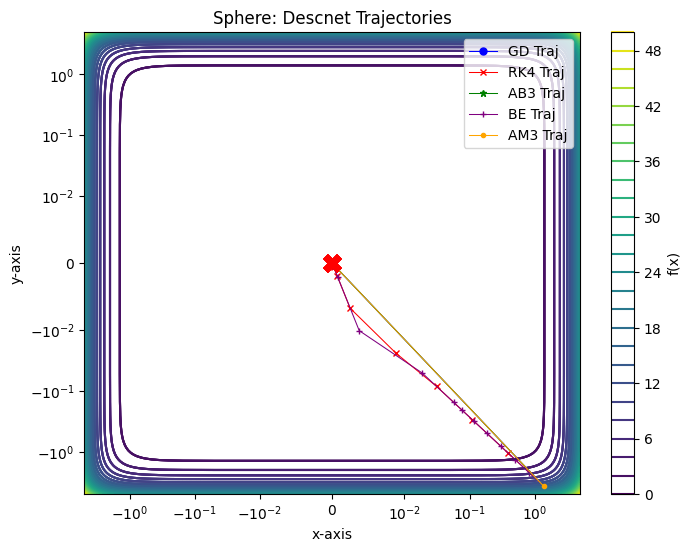

In [20]:
# GD
# plot gradient trajectory
plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_gd] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_gd] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='o', color='blue', label='GD Traj', markersize = 5, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

plt.colorbar(label='f(x)')
plt.title('GD Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# RK4
# plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_rk4] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_rk4] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='x', color='red', label='RK4 Traj', markersize = 5, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('RK4 Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# # AB3
# # plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
# plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_ab] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_ab] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='*', color='green', label='AB3 Traj', markersize = 5, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('AB3 Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# Back-Euler
# plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_be] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_be] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='+', color='purple', label='BE Traj', markersize = 5, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('B-E Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# AM3
# plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_am] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_am] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='o', color='orange', label='AM3 Traj', markersize = 3, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('Sphere: Descnet Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.legend()
plt.xscale('symlog', linthresh=1e-2)
plt.yscale('symlog', linthresh=1e-2)
plt.savefig("brent.trjectory.png")  # Save the plot
plt.show()